# A personal budget: will I run out of money?

*Beyond the scriptum — an application.*

---

The insurance company from exercises 2 and 9 collects premiums and pays out claims. You receive a
salary and pay rent, food, the occasional restaurant, and once in a while your washing machine breaks.

**It is the same problem.** Income = premiums, expenses = claims, the reserve in your account =
capital, "running out of money" = ruin. The whole apparatus from the insurance company carries over
unchanged — it is just your budget this time.

We add one question the insurance company did not have: **I am saving for a car at 100 000. Will I get
there before I go into the red?** That is two boundaries instead of one, and the problem has a
beautiful exact result — the classical **gambler's ruin**.

In this notebook you see:

- a budget model: fixed payments, daily shopping, restaurants as a compound process (exercise 5),
  breakdowns as rare large expenses
- **how large a reserve** I need so that I do not run out of money within two years
- **two boundaries**: the goal versus the red, and the exact solution of gambler's ruin as a check
- **what actually drives the risk** — and it is something other than one would expect

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def spaces(x, spec=",.0f"):
    return format(x, spec).replace(",", " ")


def poisson(lam):
    '''The number of events: a product of uniform numbers below e^-λ (exercise 3).'''
    L, p, k = math.exp(-lam), 1.0, 0
    while True:
        p *= random.random()
        if p < L:
            return k
        k += 1


# --- the budget parameters (monthly, in CZK) ---
INCOME = 38_000            # net salary
RENT = 16_000              # rent including utilities
OTHER_FIXED = 4_000        # transport, phone, subscriptions

FOOD_DAY, FOOD_SD = 230.0, 90.0          # ordinary shopping, fluctuates from day to day
RESTAURANT_MONTHLY = 7                   # how many times a month I eat out
RESTAURANT_FROM, RESTAURANT_TO = 250, 900

BREAKDOWNS_YEARLY = 2.5    # the washing machine, the fridge, a repair in the flat…
BREAKDOWN_BASE = 3_000     # nothing gets fixed for under three thousand
BREAKDOWN_MEAN = 9_000     # plus an exponential tail


def expenses_for_month(no_chance=()):
    '''Expenses for one month.

    no_chance: names of the components to be replaced by their expected value
    (used in section 4 to find out which uncertainty actually matters).
    '''
    v = RENT + OTHER_FIXED

    if "food" in no_chance:
        v += 30 * FOOD_DAY
    else:
        v += sum(max(0.0, random.gauss(FOOD_DAY, FOOD_SD)) for _ in range(30))

    if "restaurants" in no_chance:
        v += RESTAURANT_MONTHLY * (RESTAURANT_FROM + RESTAURANT_TO) / 2
    else:
        for _ in range(poisson(RESTAURANT_MONTHLY)):
            v += random.uniform(RESTAURANT_FROM, RESTAURANT_TO)

    if "breakdowns" in no_chance:
        v += BREAKDOWNS_YEARLY / 12 * (BREAKDOWN_BASE + BREAKDOWN_MEAN)
    else:
        for _ in range(poisson(BREAKDOWNS_YEARLY / 12)):
            v += BREAKDOWN_BASE + random.expovariate(1 / BREAKDOWN_MEAN)

    return v


# the exact expectation of the monthly expenses
E_EXPENSES = (RENT + OTHER_FIXED + 30 * FOOD_DAY
              + RESTAURANT_MONTHLY * (RESTAURANT_FROM + RESTAURANT_TO) / 2
              + BREAKDOWNS_YEARLY / 12 * (BREAKDOWN_BASE + BREAKDOWN_MEAN))
print(f"expected expenses per month: {spaces(E_EXPENSES)} CZK")
print(f"income {spaces(INCOME)} CZK  →  on average I put aside {spaces(INCOME - E_EXPENSES)} CZK a month")

expected expenses per month: 33 425 CZK
income 38 000 CZK  →  on average I put aside 4 575 CZK a month


## 1. What a month looks like

The model has four kinds of expense and each behaves differently:

| component | model | where from |
|---|---|---|
| rent, phone, transport | a fixed amount | — |
| ordinary shopping | 30 daily amounts, each around 230 CZK | a sum of many small ones ⟹ CLT (exercise 0) |
| restaurants | a random **number** × a random **amount** | a compound process (exercise 5) |
| breakdowns | rare, but large | Poisson (exercise 3) + an exponential tail |

Food fluctuates from day to day, but there are thirty of them, so it averages out. Breakdowns are the
opposite case: zero in most months, an occasional blow. Let us see what the distribution of the
monthly expenses as a whole looks like.

monthly expenses: mean 33 407 CZK (exact 33 425), standard deviation 6 995 CZK
in 12.8% of months the expenses exceed the income of 38 000 CZK


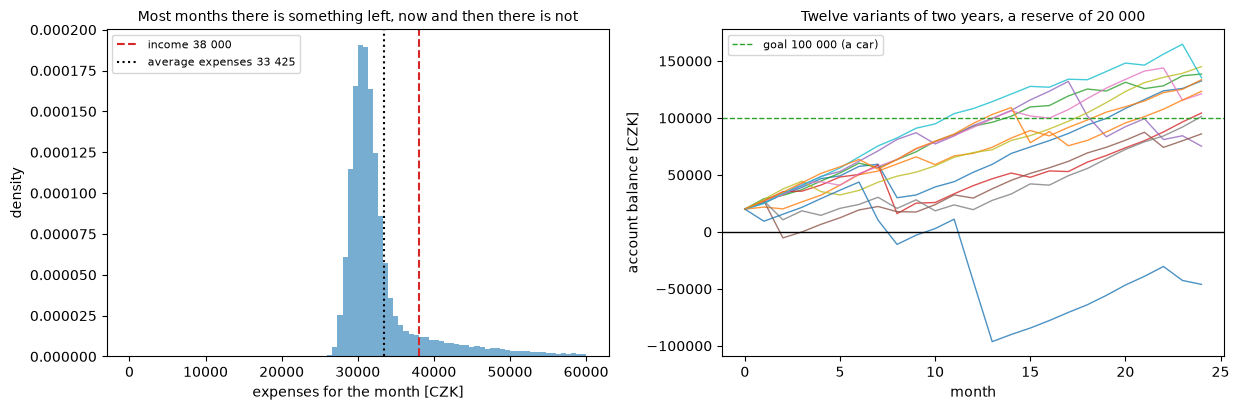

In [2]:
n = 100_000
samples = [expenses_for_month() for _ in range(n)]
m = sum(samples) / n
sd = math.sqrt(sum((x - m) ** 2 for x in samples) / (n - 1))
print(f"monthly expenses: mean {spaces(m)} CZK (exact {spaces(E_EXPENSES)}), "
      f"standard deviation {spaces(sd)} CZK")
assert abs(m - E_EXPENSES) < 5 * sd / math.sqrt(n)
print(f"in {sum(1 for x in samples if x > INCOME) / n:.1%} of months the expenses exceed the income of {spaces(INCOME)} CZK")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
w = 60_000 / 90
ax.hist(samples, bins=90, range=(0, 60_000), weights=[1 / (n * w)] * n, alpha=0.6)
ax.axvline(INCOME, color="tab:red", ls="--", label=f"income {spaces(INCOME)}")
ax.axvline(E_EXPENSES, color="k", ls=":", label=f"average expenses {spaces(E_EXPENSES)}")
ax.set_xlabel("expenses for the month [CZK]")
ax.set_ylabel("density")
ax.set_title("Most months there is something left, now and then there is not", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
random.seed(4)
for _ in range(12):
    balance, path = 20_000, [20_000]
    for _ in range(24):
        balance += INCOME - expenses_for_month()
        path.append(balance)
    ax.plot(path, lw=1, alpha=0.8)
ax.axhline(0, color="k", lw=1)
ax.axhline(100_000, color="tab:green", ls="--", lw=1, label="goal 100 000 (a car)")
ax.set_xlabel("month")
ax.set_ylabel("account balance [CZK]")
ax.set_title("Twelve variants of two years, a reserve of 20 000", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The right-hand plot is the whole problem in a single picture. Most paths rise — on average nearly five
thousand a month is put aside, after all — but some fall below zero before they climb to the goal. And
the shape of those drops gives away the culprit: they are not gradual slides but **steps**.
Breakdowns.

## 2. How large a reserve do I need?

The same question as "how much capital does the insurance company need" from exercise 9, only with
smaller numbers.

In [3]:
def runs_out(reserve, months=24, no_chance=(), M_=20_000):
    '''The fraction of runs in which the account balance ever falls below zero.'''
    cnt = 0
    for _ in range(M_):
        balance = reserve
        for _ in range(months):
            balance += INCOME - expenses_for_month(no_chance)
            if balance < 0:
                cnt += 1
                break
    return cnt / M_


print(f"{'reserve':>10s} {'in months of expenses':>22s} {'P(run out within 2 years)':>27s}")
reserves = (0, 10_000, 20_000, 40_000, 60_000, 100_000)
p_out = []
for r in reserves:
    p = runs_out(r)
    p_out.append(p)
    print(f"{spaces(r):>10s} {r / E_EXPENSES:>21.2f} {p:>27.4f}")

target = 0.01
suitable = next(r for r, p in zip(reserves, p_out) if p < target)
print(f"\nWe get under {target:.0%} risk with a reserve of around {spaces(suitable)} CZK,")
print(f"which is roughly {suitable / E_EXPENSES:.1f} months of expenses.")
print(f"\nAdvisers usually recommend a reserve of 3 to 6 months, i.e. considerably more. There is no conflict:")
print(f"our model assumes that the income always arrives. As soon as we admit the loss of")
print(f"a job, the reserve has to cover the whole of the expenses, not just their fluctuation — and the")
print(f"requirement jumps to a multiple. That is exercise 2 at the end of the notebook.")

   reserve  in months of expenses   P(run out within 2 years)


         0                  0.00                      0.2871


    10 000                  0.30                      0.1368


    20 000                  0.60                      0.0721


    40 000                  1.20                      0.0160


    60 000                  1.80                      0.0037


   100 000                  2.99                      0.0004

We get under 1% risk with a reserve of around 60 000 CZK,


which is roughly 1.8 months of expenses.

Advisers usually recommend a reserve of 3 to 6 months, i.e. considerably more. There is no conflict:
our model assumes that the income always arrives. As soon as we admit the loss of
a job, the reserve has to cover the whole of the expenses, not just their fluctuation — and the
requirement jumps to a multiple. That is exercise 2 at the end of the notebook.


## 3. Two boundaries: the goal, or the red?

Now a question the insurance company does not have. I am saving for a car at 100 000 and I have a
reserve $u_0$. What interests me is:

> Will I reach the goal before I fall into the red?

These are **two absorbing boundaries** — the goal $G$ above, zero below — and in its simple form this
is the classical **gambler's ruin** with an exact solution. The gambler starts with $u_0$ and in every
step wins a crown with probability $p$, otherwise loses it. The probability of reaching $G$ before
zero is

$$P = \frac{1 - r^{u_0}}{1 - r^{G}}, \qquad r = \frac{1-p}{p} \qquad (\text{and } P = u_0/G \text{ for } p = \tfrac12).$$

We first verify the simulator against this formula — it is the only part of the problem where we know
the exact answer.

In [4]:
def gamblers_ruin_sim(u0, G, p, M_=100_000):
    '''Simulation: ±1 per step, absorption at 0 and at G.'''
    success = 0
    for _ in range(M_):
        x = u0
        while 0 < x < G:
            x += 1 if random.random() < p else -1
        success += x >= G
    return success / M_


def gamblers_ruin_exact(u0, G, p):
    if abs(p - 0.5) < 1e-12:
        return u0 / G
    r = (1 - p) / p
    return (1 - r**u0) / (1 - r**G)


print(f"{'u_0':>5s} {'G':>5s} {'p':>6s} {'simulation':>11s} {'exact':>10s}")
for u0, G, p in ((5, 20, 0.50), (5, 20, 0.52), (10, 30, 0.48), (3, 10, 0.55)):
    sim = gamblers_ruin_sim(u0, G, p, 60_000)
    exact = gamblers_ruin_exact(u0, G, p)
    print(f"{u0:>5d} {G:>5d} {p:>6.2f} {sim:>11.5f} {exact:>10.5f}")
    assert abs(sim - exact) < 0.01

print("\nThe two-boundary simulator is verified. Now the same with a real budget,")
print("where a step is not ±1 but the monthly surplus with its whole distribution.")

  u_0     G      p  simulation      exact


    5    20   0.50     0.24940    0.25000


    5    20   0.52     0.41388    0.41317


   10    30   0.48     0.12150    0.12219
    3    10   0.55     0.52248    0.52254



The two-boundary simulator is verified. Now the same with a real budget,
where a step is not ±1 but the monthly surplus with its whole distribution.


a goal of 100 000 CZK, a horizon of 3 years

   reserve  reach the goal   fall into the red   neither


         0           0.706               0.280     0.014


    10 000           0.847               0.139     0.013


    20 000           0.920               0.070     0.010


    40 000           0.978               0.018     0.004


    60 000           0.994               0.005     0.001


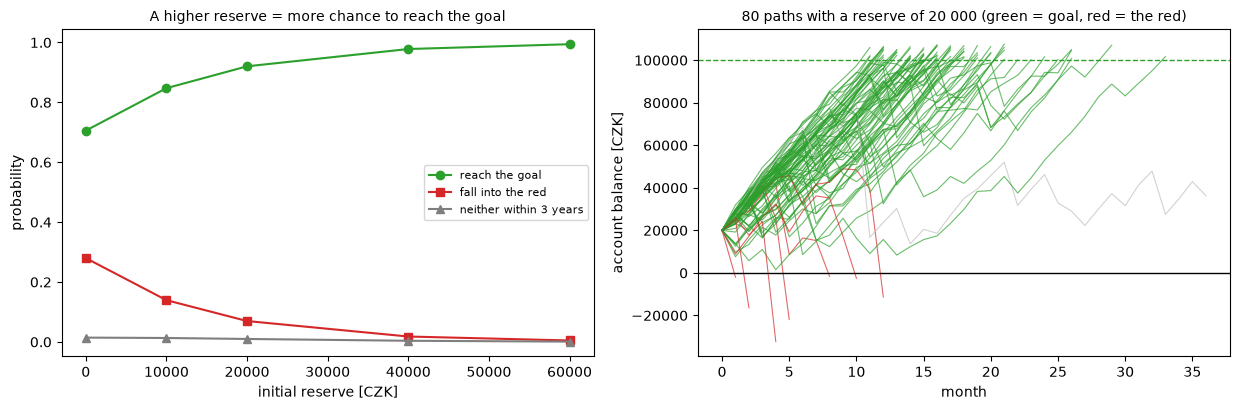

In [5]:
def reach_goal(reserve, goal_amount=100_000, months=36, no_chance=(), M_=20_000):
    '''Returns (P(reach the goal before the red), P(the red), P(neither by the end)).'''
    success = ruin = 0
    for _ in range(M_):
        balance = reserve
        for _ in range(months):
            balance += INCOME - expenses_for_month(no_chance)
            if balance < 0:
                ruin += 1
                break
            if balance >= goal_amount:
                success += 1
                break
    return success / M_, ruin / M_, 1 - (success + ruin) / M_


print(f"a goal of 100 000 CZK, a horizon of 3 years\n")
print(f"{'reserve':>10s} {'reach the goal':>15s} {'fall into the red':>19s} {'neither':>9s}")
reserves2 = (0, 10_000, 20_000, 40_000, 60_000)
results = {}
for r in reserves2:
    u, k, n_ = reach_goal(r)
    results[r] = (u, k, n_)
    print(f"{spaces(r):>10s} {u:>15.3f} {k:>19.3f} {n_:>9.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.plot(reserves2, [results[r][0] for r in reserves2], "o-", color="tab:green", label="reach the goal")
ax.plot(reserves2, [results[r][1] for r in reserves2], "s-", color="tab:red", label="fall into the red")
ax.plot(reserves2, [results[r][2] for r in reserves2], "^-", color="tab:gray", label="neither within 3 years")
ax.set_xlabel("initial reserve [CZK]")
ax.set_ylabel("probability")
ax.set_title("A higher reserve = more chance to reach the goal", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
random.seed(11)
for _ in range(80):
    balance, path = 20_000, [20_000]
    for _ in range(36):
        balance += INCOME - expenses_for_month()
        path.append(balance)
        if balance < 0 or balance >= 100_000:
            break
    color = "tab:green" if path[-1] >= 100_000 else ("tab:red" if path[-1] < 0 else "0.75")
    ax.plot(path, lw=0.8, alpha=0.7, color=color)
ax.axhline(0, color="k", lw=1)
ax.axhline(100_000, color="tab:green", ls="--", lw=1)
ax.set_xlabel("month")
ax.set_ylabel("account balance [CZK]")
ax.set_title("80 paths with a reserve of 20 000 (green = goal, red = the red)", fontsize=10)
plt.tight_layout()
plt.show()

## 4. What actually drives the risk

A practical question: **what is worth economizing on?** Eating out less? Shopping more cheaply? Or
something else?

A simple experiment gives the answer. We replace each random component in turn by its **expected
value** — that is, we take away its uncertainty but not its cost — and see by how much the risk falls.
What leaves the risk unchanged does not stand behind it.

In [6]:
print(f"reserve 20 000, a horizon of 2 years\n")
base_p = runs_out(20_000)
print(f"{'what we strip of uncertainty':>30s} {'P(run out)':>12s} {'drop':>10s}")
print(f"{'nothing (the full model)':>30s} {base_p:>12.4f} {'—':>10s}")
for component, label in (("food", "ordinary shopping"),
                         ("restaurants", "restaurants"),
                         ("breakdowns", "breakdowns and repairs")):
    p = runs_out(20_000, no_chance=(component,))
    print(f"{label:>30s} {p:>12.4f} {1 - p / base_p:>9.0%}")

p_all = runs_out(20_000, no_chance=("food", "restaurants", "breakdowns"))
print(f"{'everything (deterministic)':>30s} {p_all:>12.4f} {1 - p_all / base_p:>9.0%}")

e_breakdowns = spaces(BREAKDOWNS_YEARLY / 12 * (BREAKDOWN_BASE + BREAKDOWN_MEAN))
e_restaurants = spaces(RESTAURANT_MONTHLY * (RESTAURANT_FROM + RESTAURANT_TO) / 2)
print(f"\nStripping food or restaurants of uncertainty barely helps. Breakdowns do — even though")
print(f"they cost on average only {e_breakdowns} CZK a month, whereas restaurants cost {e_restaurants} CZK.")
print(f"\nWhat decides the risk is not how much something costs on average, but how much it FLUCTUATES.")

reserve 20 000, a horizon of 2 years



  what we strip of uncertainty   P(run out)       drop
      nothing (the full model)       0.0705          —


             ordinary shopping       0.0707       -0%


                   restaurants       0.0696        1%


        breakdowns and repairs       0.0000      100%


    everything (deterministic)       0.0000      100%

Stripping food or restaurants of uncertainty barely helps. Breakdowns do — even though
they cost on average only 2 500 CZK a month, whereas restaurants cost 4 025 CZK.

What decides the risk is not how much something costs on average, but how much it FLUCTUATES.


This is the same conclusion as with the clusters in the insurance company, translated into practical
advice: **what decides the risk is not the average cost but its variance.**

Restaurants cost nearly twice as much a month as breakdowns, and yet the risk does not stand on them —
because it is a reliable, predictable amount. Breakdowns are cheaper and at the same time more
dangerous, because they arrive all at once and in full.

The practical consequence: if you want to reduce the risk of running out of money, giving up
restaurants is **ineffective**. What is effective is either to have a reserve or to move the risk
somewhere else — which is exactly what insurance is called. That closes the circle: the insurance
company from exercise 2 exists to take over, for a fee, precisely this variance.

## Summary

| Concept | What to remember |
|---------|------------------|
| A budget = an insurance company | income ↔ premiums, expenses ↔ claims, reserve ↔ capital, the red ↔ ruin |
| A compound process | restaurants: a random number × a random amount (exercise 5) |
| Rare large expenses | breakdowns: Poisson + an exponential tail (exercises 3 and 4) |
| Two boundaries | the goal vs. the red = **gambler's ruin**, $P = (1 - r^{u_0})/(1 - r^{G})$ |
| The size of the reserve | ~2 months of expenses for a 1 % risk — but only with a certain income |
| What drives the risk | **variance, not the mean**: breakdowns are cheaper than restaurants and yet more dangerous |
| What insurance is for | moving variance onto someone who can bear it (and who solves exercise 9) |

### Try it yourself

1. **Irregular income.** Instead of a fixed salary let the income fluctuate (odd jobs, invoices). By
   how much does the necessary reserve grow at the same expectation?
2. **Losing a job.** Add a risk that with probability 2 % a month you lose your job and for the next 4
   months have only half the income. Does the recommended reserve of 3–6 months of expenses now come
   out?
3. **Inflation.** Let expenses grow by 0.3 % a month and the income once a year in a jump. How does
   the time to the goal change?
4. Verify the gambler's ruin formula for an asymmetric walk with a step of $\pm a$ instead of $\pm 1$.
   Does it still hold?
5. Compute the **mean time** to reaching the goal (not just the probability) and compare it with the
   naive estimate $G/(\text{monthly surplus})$. Why is reality longer? (Hint: Jensen's inequality.)
6. Introduce saving with interest: the surplus appreciates by 0.4 % a month. This is a
   **multiplicative** process — does it change the problem substantially, or not?
7. Replace the breakdowns with insurance: pay 1 200 CZK a month extra and let breakdowns be free. Does
   it pay off in terms of risk? And in terms of the average?